In [ ]:

import pandas as pd
import numpy as np
from glob import glob
import datetime as dt
import matplotlib.pyplot as plt

# Load the data

# 2025_02_Richter_Experimentalprocedureenvironmental

In [16]:
pth = "OpenLAB Data/2025_02_Richter_Experimentalprocedureenvironmental/Data/tiltmeter_trigger"

# d = pd.read_csv(pth + '/tiltmeter_2025_05_05_T11_30_41.csv')
# all files in the directory
files = glob(pth + '/*.csv')
for file in files:
    dfs = [pd.read_csv(file) for file in files]

In [18]:
dfs[1].head()

,Timestamp,G_TILX_PE11_CB1100_0,G_TILX_PE12_CB1100_0,G_TILX_PE13_CB1100_0,G_TILX_PE21_CB0400_0,G_TILX_PE22_CB0400_0,G_TILX_PE23_CB0400_0
0,2025-05-05 12:34:35.600,0.0,-0.015481,0.003880,-0.001462,0.010424,0.003407
1,2025-05-05 12:34:35.800,0.0,-0.015439,0.003878,-0.001156,0.008699,0.003034
2,2025-05-05 12:34:36.000,0.0,-0.015269,0.003870,-0.000719,0.006027,0.002370
3,2025-05-05 12:34:36.200,0.0,-0.014747,0.003836,-0.000336,0.003437,0.001587
4,2025-05-05 12:34:36.400,0.0,-0.013493,0.003731,-0.000051,0.001613,0.000890


In [ ]:
dfs[0].describe(percentiles=[0.01, 0.99])
# dfs[0].tail()
df = pd.concat(dfs, ignore_index=True)

In [42]:
df.shape
df.query('Timestamp > "2025-05-05 00:30:00"')

,Timestamp,G_TILX_PE11_CB1100_0,G_TILX_PE12_CB1100_0,G_TILX_PE13_CB1100_0,G_TILX_PE21_CB0400_0,G_TILX_PE22_CB0400_0,G_TILX_PE23_CB0400_0
0,2025-05-05 11:30:41.000,0.003795,0.000002,-2.610168e-07,-0.009171,-0.006616,0.001086
1,2025-05-05 11:30:41.200,0.003763,0.000002,-1.963060e-06,-0.008870,-0.003598,0.001837
2,2025-05-05 11:30:41.400,0.003661,0.000002,-1.060675e-05,-0.008436,0.001080,0.003172
3,2025-05-05 11:30:41.600,0.003414,0.000002,-4.479321e-05,-0.008027,0.005612,0.004747
4,2025-05-05 11:30:41.800,0.002954,0.000002,-1.500949e-04,-0.007611,0.008808,0.006145
...,...,...,...,...,...,...,...
14845,2025-05-07 18:00:38.000,0.006501,0.007269,1.553124e-03,0.006899,-0.010734,-0.011078
14846,2025-05-07 18:00:38.200,0.007242,0.009612,8.700593e-04,0.008431,-0.010071,-0.010142
14847,2025-05-07 18:00:38.400,0.007552,0.010866,4.008557e-04,0.009779,-0.009311,-0.008825
14848,2025-05-07 18:00:38.600,0.007652,0.011388,1.512633e-04,0.010691,-0.008663,-0.007468


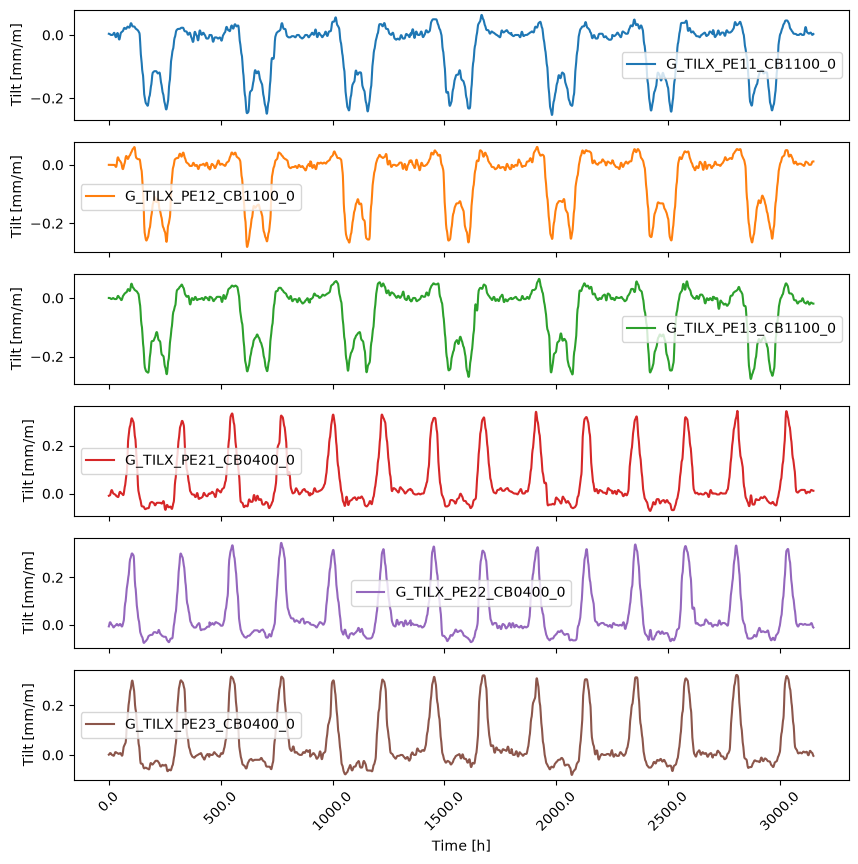

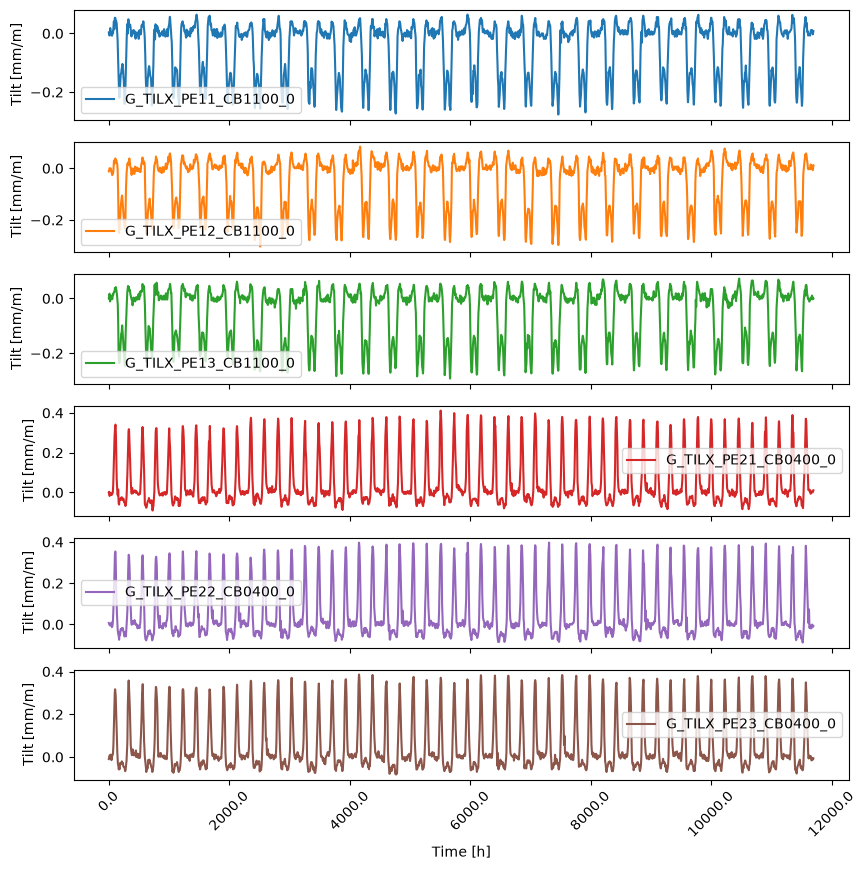

In [ ]:
# for i in range(3):
#     dfs[i].plot()

# True means separated plots for individual sensors
subplots = True  
df1 = df.query('Timestamp < "2025-05-06 00:00:00"')
df2 = df.query('Timestamp >= "2025-05-06 23:00:00"')

def plot_data(df, subplots):
    plot = df.plot(x='Timestamp', subplots=subplots, figsize=(10, 10))
    # rotate x-axis labels for better readability
    if subplots is False:
        plot = [plot]

    for ax in plot:
            ax.set_xticklabels(ax.get_xticks(), rotation=45)
            ax.set_xlabel('Time [h]')
            ax.set_ylabel('Tilt [mm/m]') # mrad

plot_data(df1, subplots)
plot_data(df2, subplots)

# OpenLAB Data/2025_05_06_openLAB_tests

In [ ]:
path = "OpenLAB Data/2025_05_06_openLAB_tests/Data"
file = path + '/MD_2025_05_06_09_08_25.txt'

columns = [
    "Zeit_1",
    "DMS_1",
    "Zeit_2",
    "Kraft_N",
    "Kraft_A",
    "IWA",
    "Temperatur_Bruecke",
    "Temperatur_Umgebung",
    "Zeit_3",
    "LWA_1",
    "LWA_2",
    "LWA_3",
    "Zeit_4",
    "LWA_4",
    "LWA_5",
    "NMA_5",
    "F_gesamt",
]

# Read everything as strings first
with open(file, encoding="latin1") as f:
    lines = f.readlines()

# Find first real measurement line
start = next(
    i for i, line in enumerate(lines)
    if line.startswith("0\t")
)

# Get measurement lines
rows = []

for line in lines[start:]:
    parts = line.rstrip("\r\n").split("\t")

    # Only accept rows with exactly 17 values
    if len(parts) == 17:
        rows.append(parts)

# DataFrame
df = pd.DataFrame(rows, columns=columns)

# Convert comma decimals to floats
for col in df.columns:
    df[col] = (
        df[col]
        .str.replace(",", ".", regex=False)
        .astype(float)
    )

print(df.shape)
print(df.head())
print(df.dtypes)

path = "OpenLAB Data/2025_05_06_openLAB_tests/Data"
path + '/MD_2025_05_06_09_08_25.txt',
dft = pd.read_csv(
    path + '/MD_2025_05_06_09_08_25.txt',
    sep="\t",
    skiprows=36,       # adjust if necessary
    decimal=",",
    encoding="latin1",
    header=None
)

dft.columns = columns
dft = dft.drop(columns=["Extra"])
dft.head()

(0, 17)
Empty DataFrame
Columns: [Zeit_1, DMS_1, Zeit_2, Kraft_N, Kraft_A, IWA, Temperatur_Bruecke, Temperatur_Umgebung, Zeit_3, LWA_1, LWA_2, LWA_3, Zeit_4, LWA_4, LWA_5, NMA_5, F_gesamt]
Index: []
Zeit_1                 float64
DMS_1                  float64
Zeit_2                 float64
Kraft_N                float64
Kraft_A                float64
IWA                    float64
Temperatur_Bruecke     float64
Temperatur_Umgebung    float64
Zeit_3                 float64
LWA_1                  float64
LWA_2                  float64
LWA_3                  float64
Zeit_4                 float64
LWA_4                  float64
LWA_5                  float64
NMA_5                  float64
F_gesamt               float64
dtype: object


,Zeit_1,DMS_1,Zeit_2,Kraft_N,Kraft_A,IWA,Temperatur_Bruecke,Temperatur_Umgebung,Zeit_3,LWA_1,LWA_2,LWA_3,Zeit_4,LWA_4,LWA_5,NMA_5,F_gesamt
0,0.0,-0.56840,0.0,-0.01421,0.2799,-0.000120,11.09,13.68,0.0,-0.00211,-0.00088,0.00299,0.0,0.05363,-0.05345,-1000000,0.2657
1,0.1,-0.29710,0.1,-0.01392,0.2839,-0.000130,11.11,13.67,0.1,0.00313,-0.00562,-0.00639,0.1,0.02324,-0.04439,-1000000,0.2699
2,0.2,-0.04091,0.2,-0.01534,0.2764,-0.000072,11.11,13.68,0.2,0.00077,-0.01277,-0.00690,0.2,0.06701,-0.07119,-1000000,0.2610
3,0.3,-0.79660,0.3,-0.00949,0.2452,-0.000110,11.10,13.68,0.3,-0.00168,-0.00205,-0.00539,0.3,0.01111,-0.05519,-1000000,0.2357
4,0.4,-0.17220,0.4,-0.01460,0.2745,-0.000150,11.13,13.67,0.4,-0.00139,-0.00895,-0.00077,0.4,0.00771,-0.01691,-1000000,0.2599
